In [2]:
%pip install -q numpy==2.3.5 scipy==1.17.0 scikit-learn==1.8.0 pandas==2.2.3 joblib==1.5.3 matplotlib==3.10.8 zarr==3.4.2

In [3]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"

import json
import math
import urllib.request
import concurrent.futures
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zarr

from scipy.signal import welch
from scipy.special import expit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
)
from threadpoolctl import threadpool_limits

root = Path("/content/ParkinSense_rebuild")
root.mkdir(parents=True, exist_ok=True)

groups = {
    (0, 1): "10,100,107,11,12,18,26,3,36,40,43,48,53,55,56,58,6,84,86,87,93,96",
    (0, 2): "104,17,19,21,22,23,31,34,35,39,4,42,44,47,50,54,57,71,77,81,82,88",
    (0, 3): "105,109,14,24,27,37,45,51,52,63,64,67,69,72,73,75,79,8,85,94,98",
    (0, 4): "1,102,103,108,110,15,16,2,32,38,41,59,60,62,65,68,70,76,90,92,95",
    (0, 5): "101,106,13,25,28,29,33,46,49,5,61,7,74,78,80,83,89,9,91,97,99",
    (1, 1): "112,116,118,124,127,137,138,141,145,147,153,156,163,166,173,176,183,191,201,206,210,222,229,242,243,245,253,255,258,269,272,274",
    (1, 2): "119,121,131,132,134,135,136,146,165,168,172,177,181,185,189,192,195,203,224,232,234,240,244,247,249,251,261,264,265,266,273,276",
    (1, 3): "114,125,126,128,133,143,149,157,159,160,161,169,174,178,182,187,188,194,196,200,209,211,218,219,220,223,236,238,241,248,252,270",
    (1, 4): "113,115,122,123,130,140,142,148,151,152,154,167,171,184,186,190,198,199,202,205,215,216,221,225,227,239,250,256,260,262,263,275",
    (1, 5): "117,120,129,139,144,155,158,162,164,170,175,179,180,193,197,204,207,208,212,213,214,217,226,233,235,237,246,254,257,259,267,271",
}

rows = []

for (label, fold), numbers in groups.items():
    for number in numbers.split(","):
        rows.append({
            "id": f"sub-{number}",
            "pd": label,
            "fold": fold,
        })

cohort = pd.DataFrame(rows).sort_values("id").reset_index(drop=True)

assert len(cohort) == 267
assert cohort["id"].is_unique
assert cohort["pd"].sum() == 160

cohort.to_csv(root / "cohort.csv", index=False)

display(
    pd.crosstab(cohort["fold"], cohort["pd"], margins=True)
    .rename(columns={0: "Control", 1: "Parkinson's"})
)

pd,Control,Parkinson's,All
fold,,,
1,22,32,54
2,22,32,54
3,21,32,53
4,21,32,53
5,21,32,53
All,107,160,267


In [4]:
sites = ["Fz", "C3", "Cz", "C4"]
data_base = "https://nemar.s3.us-east-2.amazonaws.com/on008768/zarr/"

def fetch(url, destination):
    destination = Path(destination)

    if destination.exists():
        return destination.read_bytes()

    destination.parent.mkdir(parents=True, exist_ok=True)

    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=90) as response:
                content = response.read()

            temporary = destination.with_suffix(".partial")
            temporary.write_bytes(content)
            temporary.replace(destination)

            return content

        except Exception:
            if attempt == 2:
                raise

def download_person(sid):
    output = root / "signals" / f"{sid}.npz"

    if output.exists():
        return sid, "cached"

    recording = f"{sid}/ses-01/eeg/{sid}_ses-01_task-rest_eeg.zarr"
    base = data_base + recording + "/eeg_250hz/"
    local = root / "stores" / sid

    group_metadata = json.loads(
        fetch(base + "zarr.json", local / "group.json")
    )

    array_metadata = json.loads(
        fetch(base + "0/zarr.json", local / "0/zarr.json")
    )

    group_attributes = group_metadata["attributes"]
    array_attributes = array_metadata["attributes"]

    assert group_attributes["rate"] == 250
    assert group_attributes["original_rate"] == 500
    assert array_attributes["kind"] == "signal"
    assert array_attributes["usable_for_inference"]

    channel_names = [
        channel["label"]
        for channel in group_attributes["channels"]
    ]

    indices = [channel_names.index(site) for site in sites]

    assert all(
        group_attributes["channels"][i]["unit"] == "uV"
        for i in indices
    )

    shape = array_metadata["shape"]
    chunks = array_metadata["chunk_grid"]["configuration"]["chunk_shape"]

    for i in range(math.ceil(shape[0] / chunks[0])):
        for j in range(math.ceil(shape[1] / chunks[1])):
            chunk_path = f"0/c/{i}/{j}"
            fetch(base + chunk_path, local / chunk_path)

    array = zarr.open_array(
        str(local / "0"),
        mode="r",
        zarr_format=3,
    )

    digital = np.asarray(array.oindex[indices, :], dtype=float)
    scale = np.asarray(array_attributes["scale"])[indices, None]
    offset = np.asarray(array_attributes["offset"])[indices, None]

    signal = digital * scale + offset

    output.parent.mkdir(parents=True, exist_ok=True)

    np.savez_compressed(
        output,
        x=signal,
        channels=np.array(sites),
        fs=250,
        original_fs=group_attributes["original_rate"],
        source=recording,
    )

    return sid, "downloaded"

errors = []

with concurrent.futures.ThreadPoolExecutor(max_workers=12) as pool:
    futures = {
        pool.submit(download_person, sid): sid
        for sid in cohort["id"]
    }

    for completed, future in enumerate(
        concurrent.futures.as_completed(futures),
        start=1,
    ):
        sid = futures[future]

        try:
            _, status = future.result()

            if completed % 10 == 0 or completed == len(cohort):
                print(
                    f"{completed}/{len(cohort)} completed",
                    flush=True,
                )

        except Exception as error:
            errors.append({
                "id": sid,
                "error": str(error),
            })
            print(f"Failed: {sid}: {error}", flush=True)

(root / "download_errors.json").write_text(
    json.dumps(errors, indent=2)
)

if errors:
    raise RuntimeError(
        f"{len(errors)} downloads failed. Rerun this cell to retry."
    )

print("All 267 recordings are available.")

10/267 completed
20/267 completed
30/267 completed
40/267 completed
50/267 completed
60/267 completed
70/267 completed
80/267 completed
90/267 completed
100/267 completed
110/267 completed
120/267 completed
130/267 completed
140/267 completed
150/267 completed
160/267 completed
170/267 completed
180/267 completed
190/267 completed
200/267 completed
210/267 completed
220/267 completed
230/267 completed
240/267 completed
250/267 completed
260/267 completed
267/267 completed
All 267 recordings are available.


In [5]:
feature_names = [
    "relative_delta",
    "relative_theta",
    "relative_alpha",
    "relative_beta",
    "theta_alpha_ratio",
    "alpha_peak_hz",
]

def extract_features(signal, fs=250):
    samples_per_window = 4 * fs
    usable_length = (
        signal.shape[1] // samples_per_window
    ) * samples_per_window

    windows = signal[:, :usable_length].reshape(
        len(sites),
        -1,
        samples_per_window,
    )

    good = (
        np.isfinite(windows).all(axis=-1)
        & (np.ptp(windows, axis=-1) < 250)
        & (windows.std(axis=-1) > 0.5)
    )

    frequencies, power = welch(
        windows,
        fs=fs,
        nperseg=samples_per_window,
        detrend="linear",
        axis=-1,
    )

    features = []

    for channel_index in range(len(sites)):
        if good[channel_index].sum() < 10:
            features.append(np.full(6, np.nan))
            continue

        spectrum = np.median(
            power[channel_index, good[channel_index]],
            axis=0,
        )

        band_power = np.array([
            spectrum[
                (frequencies >= low) & (frequencies < high)
            ].sum()
            for low, high in [
                (1, 4),
                (4, 8),
                (8, 13),
                (13, 30),
            ]
        ])

        relative_power = band_power / band_power.sum()
        theta_alpha = band_power[1] / max(band_power[2], 1e-20)

        alpha_mask = (
            (frequencies >= 8)
            & (frequencies < 13)
        )

        alpha_peak = frequencies[alpha_mask][
            spectrum[alpha_mask].argmax()
        ]

        features.append(
            np.r_[relative_power, theta_alpha, alpha_peak]
        )

    return (
        np.asarray(features).ravel(),
        good.sum(axis=1),
        windows.shape[1],
    )

feature_rows = []
quality_rows = []

for number, row in enumerate(cohort.itertuples(), start=1):
    with np.load(root / "signals" / f"{row.id}.npz") as recording:
        assert list(recording["channels"]) == sites
        assert int(recording["fs"]) == 250

        vector, counts, total = extract_features(recording["x"])

    feature_rows.append(vector)

    for site, count in zip(sites, counts):
        quality_rows.append({
            "id": row.id,
            "channel": site,
            "good_windows": int(count),
            "total_windows": int(total),
        })

    if number % 40 == 0 or number == len(cohort):
        print(f"Extracted {number}/{len(cohort)}", flush=True)

X = np.asarray(feature_rows)
y = cohort["pd"].to_numpy()
folds = cohort["fold"].to_numpy()

assert X.shape == (267, 24)

quality = pd.DataFrame(quality_rows)
quality.to_csv(root / "channel_quality.csv", index=False)

np.savez_compressed(
    root / "features.npz",
    X=X,
    ids=cohort["id"].to_numpy(dtype=str),
    y=y,
    folds=folds,
    sites=np.array(sites),
)

columns = [
    f"{site}_{feature}"
    for site in sites
    for feature in feature_names
]

feature_table = pd.concat(
    [cohort, pd.DataFrame(X, columns=columns)],
    axis=1,
)

feature_table.to_csv(root / "features.csv", index=False)

print("Feature matrix:", X.shape)
print("Participants with complete features:", np.isfinite(X).all(axis=1).sum())

display(feature_table.head())

Extracted 40/267
Extracted 80/267
Extracted 120/267
Extracted 160/267
Extracted 200/267
Extracted 240/267
Extracted 267/267
Feature matrix: (267, 24)
Participants with complete features: 267


,id,pd,fold,Fz_relative_delta,Fz_relative_theta,Fz_relative_alpha,Fz_relative_beta,Fz_theta_alpha_ratio,Fz_alpha_peak_hz,C3_relative_delta,...,Cz_relative_alpha,Cz_relative_beta,Cz_theta_alpha_ratio,Cz_alpha_peak_hz,C4_relative_delta,C4_relative_theta,C4_relative_alpha,C4_relative_beta,C4_theta_alpha_ratio,C4_alpha_peak_hz
0,sub-1,0,4,0.374524,0.139763,0.106294,0.379419,1.314867,10.00,0.306893,...,0.131874,0.242477,1.616918,8.25,0.179370,0.096247,0.078361,0.646022,1.228248,10.75
1,sub-10,0,1,0.869881,0.045373,0.029997,0.054749,1.512585,9.00,0.560627,...,0.066165,0.115129,0.999029,8.25,0.666134,0.078376,0.084452,0.171038,0.928056,9.25
2,sub-100,0,1,0.898957,0.050607,0.027267,0.023169,1.855985,8.25,0.864628,...,0.031255,0.025151,1.659471,8.25,0.863831,0.059989,0.043779,0.032401,1.370252,8.25
3,sub-101,0,5,0.362551,0.085782,0.205827,0.345841,0.416767,8.50,0.413353,...,0.217483,0.415666,0.488948,9.75,0.491658,0.100451,0.162914,0.244977,0.616589,12.50
4,sub-102,0,4,0.279888,0.096961,0.168748,0.454402,0.574590,12.50,0.280548,...,0.148473,0.377888,0.704073,12.50,0.333779,0.137624,0.131118,0.397479,1.049622,12.50


In [6]:
def fit_lda(X_train, y_train, shrinkage=0.2):
    good = np.isfinite(X_train).all(axis=1)
    X_train = X_train[good]
    y_train = y_train[good]

    if min(np.bincount(y_train, minlength=2)) < 2:
        raise ValueError("Too few training participants in one class.")

    mean = X_train.mean(axis=0)
    scale = X_train.std(axis=0)
    scale[scale < 1e-12] = 1

    standardized = (X_train - mean) / scale

    mean_control = standardized[y_train == 0].mean(axis=0)
    mean_pd = standardized[y_train == 1].mean(axis=0)

    residual = standardized - np.where(
        y_train[:, None] == 1,
        mean_pd,
        mean_control,
    )

    covariance = (
        residual.T @ residual
        / max(len(y_train) - 2, 1)
    )

    covariance = (
        (1 - shrinkage) * covariance
        + shrinkage
        * np.trace(covariance)
        / len(mean)
        * np.eye(len(mean))
        + 1e-8 * np.eye(len(mean))
    )

    weights = np.linalg.solve(
        covariance,
        mean_pd - mean_control,
    )

    bias = -0.5 * (mean_control + mean_pd) @ weights

    return {
        "mean": mean,
        "scale": scale,
        "weights": weights,
        "bias": bias,
        "shrinkage": shrinkage,
    }

def predict_lda(model, X_test):
    valid = np.isfinite(X_test).all(axis=1)
    scores = np.full(len(X_test), np.nan)

    standardized = (
        X_test[valid] - model["mean"]
    ) / model["scale"]

    scores[valid] = expit(
        standardized @ model["weights"]
        + model["bias"]
    )

    return scores

def calculate_metrics(target, scores):
    valid = np.isfinite(scores)
    positive = scores > 0.5
    negative = scores <= 0.5

    tn = int(np.sum((target == 0) & negative))
    fp = int(np.sum((target == 0) & positive))
    fn = int(np.sum((target == 1) & negative))
    tp = int(np.sum((target == 1) & positive))

    sensitivity = tp / np.sum(target == 1)
    specificity = tn / np.sum(target == 0)

    return {
        "n": len(target),
        "accuracy": (tp + tn) / len(target),
        "balanced_accuracy": (sensitivity + specificity) / 2,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "coverage": float(valid.mean()),
        "scorable_accuracy": (
            (tp + tn) / valid.sum()
            if valid.any()
            else None
        ),
        "roc_auc": (
            float(roc_auc_score(target[valid], scores[valid]))
            if len(np.unique(target[valid])) == 2
            else None
        ),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "no_result_control": int(np.sum((target == 0) & ~valid)),
        "no_result_pd": int(np.sum((target == 1) & ~valid)),
    }

In [7]:
held_out_scores = np.full(len(cohort), np.nan)
fold_results = []

with threadpool_limits(limits=1):
    for fold in range(1, 6):
        training = folds != fold
        testing = folds == fold

        assert set(cohort.loc[training, "id"]).isdisjoint(
            set(cohort.loc[testing, "id"])
        )

        model = fit_lda(
            X[training],
            y[training],
            shrinkage=0.2,
        )

        held_out_scores[testing] = predict_lda(
            model,
            X[testing],
        )

        fold_metrics = calculate_metrics(
            y[testing],
            held_out_scores[testing],
        )

        fold_results.append({
            "fold": fold,
            **fold_metrics,
        })

        print(
            f"Fold {fold}: "
            f"accuracy={fold_metrics['accuracy']:.1%}, "
            f"balanced accuracy={fold_metrics['balanced_accuracy']:.1%}",
            flush=True,
        )

metrics = calculate_metrics(y, held_out_scores)

predictions = cohort.copy()
predictions["score"] = held_out_scores
predictions["prediction"] = np.where(
    np.isfinite(held_out_scores),
    np.where(held_out_scores > 0.5, "PD", "Control"),
    "No result",
)

predictions.to_csv(
    root / "held_out_predictions.csv",
    index=False,
)

pd.DataFrame(fold_results).to_csv(
    root / "fold_metrics.csv",
    index=False,
)

(root / "metrics.json").write_text(
    json.dumps(metrics, indent=2)
)

for name in [
    "accuracy",
    "balanced_accuracy",
    "sensitivity",
    "specificity",
    "coverage",
]:
    print(f"{name.replace('_', ' ').title()}: {metrics[name]:.1%}")

print(f"ROC AUC: {metrics['roc_auc']:.3f}")

Fold 1: accuracy=64.8%, balanced accuracy=68.9%
Fold 2: accuracy=70.4%, balanced accuracy=70.7%
Fold 3: accuracy=66.0%, balanced accuracy=65.3%
Fold 4: accuracy=67.9%, balanced accuracy=65.3%
Fold 5: accuracy=73.6%, balanced accuracy=75.7%
Accuracy: 68.5%
Balanced Accuracy: 69.3%
Sensitivity: 65.6%
Specificity: 72.9%
Coverage: 100.0%
ROC AUC: 0.738


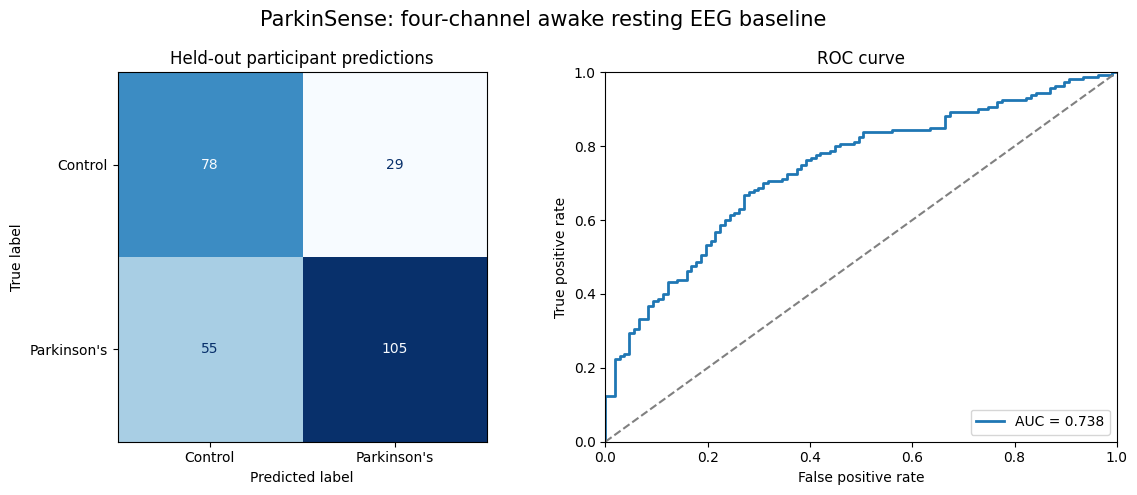

Metric checks passed.
Confusion matrix:
[[ 78  29]
 [ 55 105]]


In [8]:
valid = np.isfinite(held_out_scores)

assert valid.all(), (
    "Some recordings could not be scored. "
    "Inspect channel_quality.csv before comparing results."
)

predicted_labels = (held_out_scores > 0.5).astype(int)

assert np.isclose(
    accuracy_score(y, predicted_labels),
    metrics["accuracy"],
)

assert np.isclose(
    balanced_accuracy_score(y, predicted_labels),
    metrics["balanced_accuracy"],
)

matrix = confusion_matrix(
    y,
    predicted_labels,
    labels=[0, 1],
)

assert matrix.sum() == 267

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Control", "Parkinson's"],
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d",
)

axes[0].set_title("Held-out participant predictions")

false_positive_rate, true_positive_rate, _ = roc_curve(
    y,
    held_out_scores,
)

axes[1].plot(
    false_positive_rate,
    true_positive_rate,
    linewidth=2,
    label=f"AUC = {metrics['roc_auc']:.3f}",
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
)

axes[1].set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="ROC curve",
    xlim=(0, 1),
    ylim=(0, 1),
)

axes[1].legend(loc="lower right")

fig.suptitle(
    "ParkinSense: four-channel awake resting EEG baseline",
    fontsize=15,
)

fig.tight_layout()

fig.savefig(
    root / "baseline_results.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Metric checks passed.")
print("Confusion matrix:")
print(matrix)

In [9]:
with threadpool_limits(limits=1):
    final_model = fit_lda(X, y, shrinkage=0.2)

bundle = {
    "estimator": final_model,
    "channels": sites,
    "reference": "Pz",
    "sampling_rate": 250,
    "features_per_channel": feature_names,
    "window_seconds": 4,
    "minimum_good_windows_per_channel": 10,
    "threshold": 0.5,
    "dataset": "OpenNeuro ds008768 via NEMAR",
    "scope": "Awake resting EEG in already-diagnosed participants",
}

joblib.dump(
    bundle,
    root / "four_channel_lda.joblib",
)

print("Saved model:", root / "four_channel_lda.joblib")
print("Saved results:", root)

Saved model: /content/ParkinSense_rebuild/four_channel_lda.joblib
Saved results: /content/ParkinSense_rebuild


In [10]:
from google.colab import files

files.download(str(root / "metrics.json"))
files.download(str(root / "held_out_predictions.csv"))
files.download(str(root / "fold_metrics.csv"))
files.download(str(root / "baseline_results.png"))
files.download(str(root / "four_channel_lda.joblib"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
files.download(str(root / "channel_quality.csv"))
files.download(str(root / "cohort.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>